In [1]:
import cv2 
import numpy as np
import matplotlib.pyplot as plt

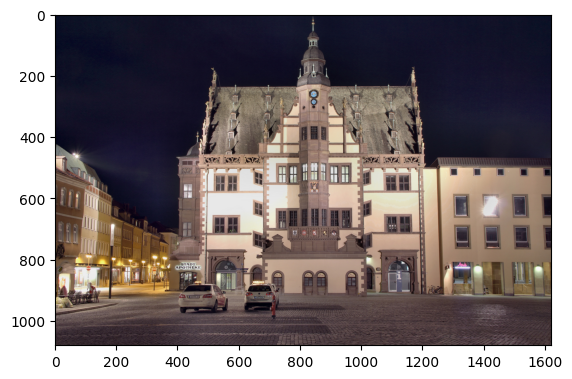

In [28]:
import os
sch_path = "Schweinfurt.jpg" if os.path.exists("Schweinfurt.jpg") else r"C:\Users\USER\OneDrive - GJU\Desktop\4th Year\MI 2\Homeworks\Schweinfurt.jpg"
image = cv2.imread(sch_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
plt.imshow(image)

dst max: 1.201412e+08
dst mean: 50894.625


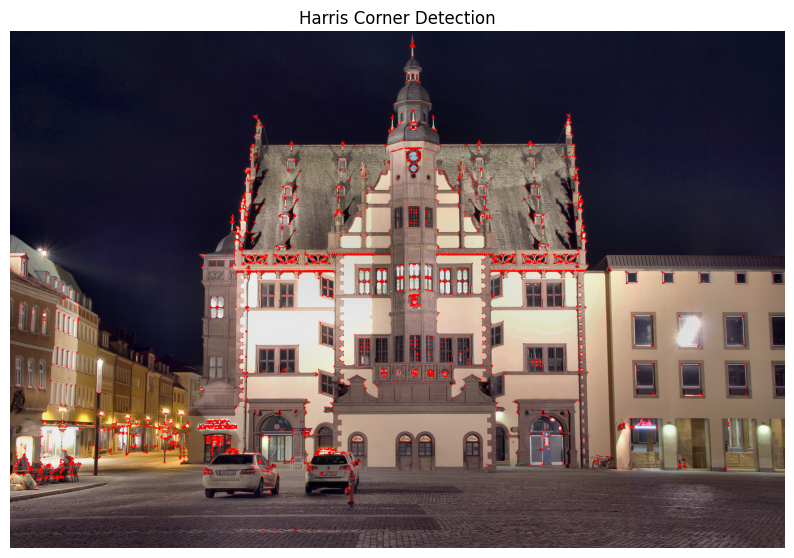

In [105]:
# Harris Corner Detection  x1 sacle 
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
gray_float = np.float32(gray)
dst = cv2.cornerHarris(gray_float, blockSize=3, ksize= 3, k=0.04)
image_with_corners = image.copy() 
image_with_corners[dst > 0.01 * dst.max()] = [255, 0, 0]
print("dst max:", dst.max())
print("dst mean:", dst.mean())
plt.figure(figsize=(10, 8)) 
plt.imshow(image_with_corners)
plt.title('Harris Corner Detection')
plt.axis('off')
plt.show()

(np.float64(-0.5), np.float64(2429.5), np.float64(1619.5), np.float64(-0.5))

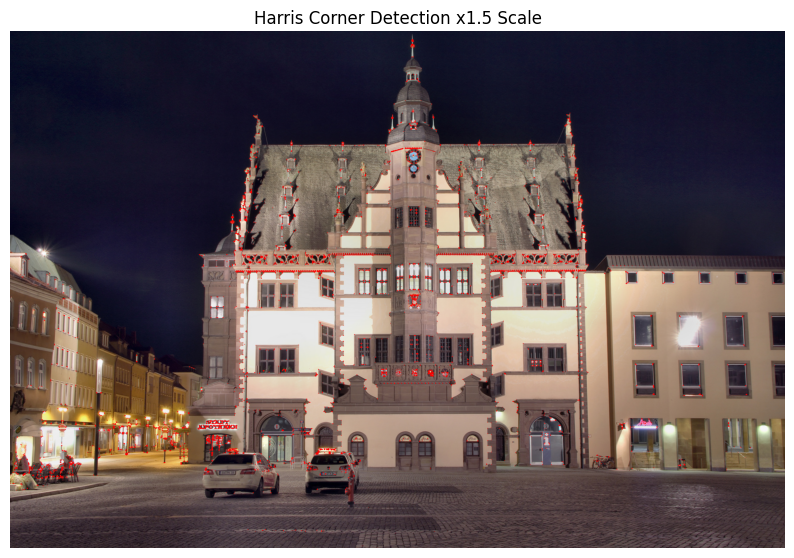

In [106]:
# Harris Corner Detection x1.5 scale
resized_image = cv2.resize(image, None, fx=1.5, fy=1.5, interpolation=cv2.INTER_LINEAR)
gray_resized = cv2.cvtColor(resized_image, cv2.COLOR_BGR2GRAY)
gray_resized_float = np.float32(gray_resized)
dst_resized = cv2.cornerHarris(gray_resized_float, blockSize=3, ksize= 3, k=0.04)
resized_image_with_corners = resized_image.copy()
resized_image_with_corners[dst_resized > 0.01 * dst_resized.max()] = [255, 0, 0]
plt.figure(figsize=(10, 8))  
plt.imshow(resized_image_with_corners)
plt.title('Harris Corner Detection x1.5 Scale')
plt.axis('off')

Even when the output image is displayed without any scaling in VS Code, the ×1.5 scaled image still results in fewer detected corners. This behavior is consistent with the fact that the Harris corner detector is not scale-invariant or covariant.

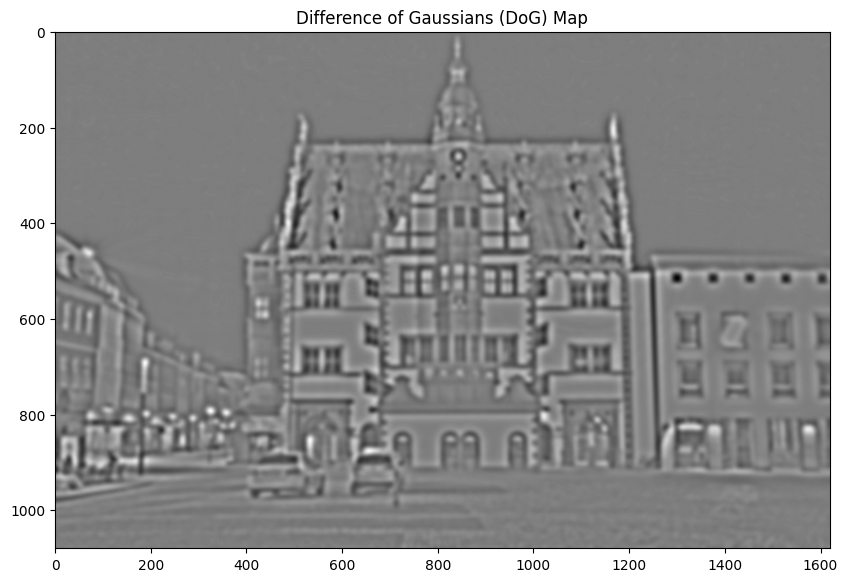

In [116]:
# DoG blob detection
blur1 = cv2.GaussianBlur(gray, (0, 0), sigmaX=5.0)
blur2 = cv2.GaussianBlur(gray, (0, 0), sigmaX=9.0)  
dog = blur1.astype(np.float32) - blur2.astype(np.float32)
dog_vis = cv2.normalize(dog, None, 0, 255, cv2.NORM_MINMAX, cv2.CV_8U)

plt.figure(figsize=(10, 8))  
plt.imshow(dog_vis, cmap='gray')
plt.title('Difference of Gaussians (DoG) Map')
plt.show()

Text(0.5, 1.0, 'Blobs')

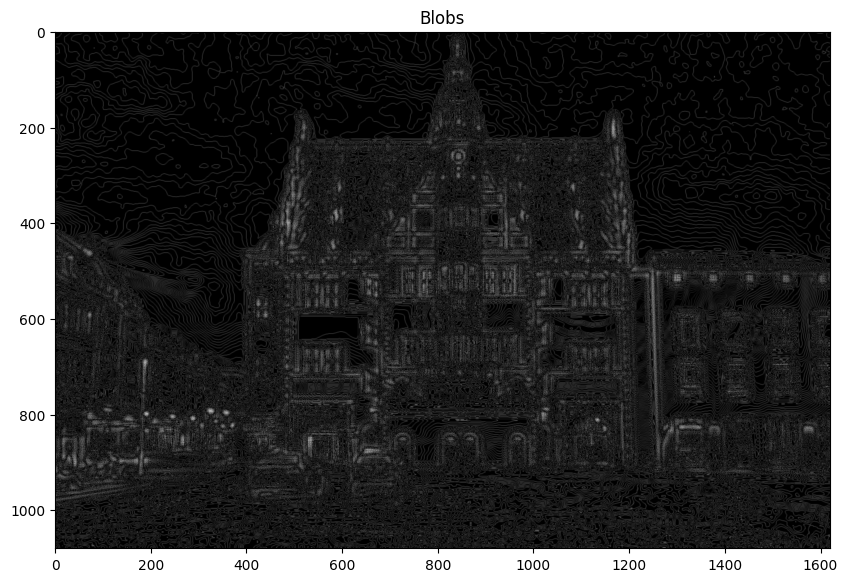

In [ ]:
#blob detection using Laplacian of Gaussian (LoG) on x1 scale 
lap_blob = cv2.Laplacian(blob_blur, cv2.CV_64F, ksize= 3)
lap_blob = cv2.convertScaleAbs(lap_blob)
plt.figure(figsize=(10, 8)) 
plt.imshow(lap_blob, cmap='gray')
plt.title('Laplacian: Blobs 1 scale')

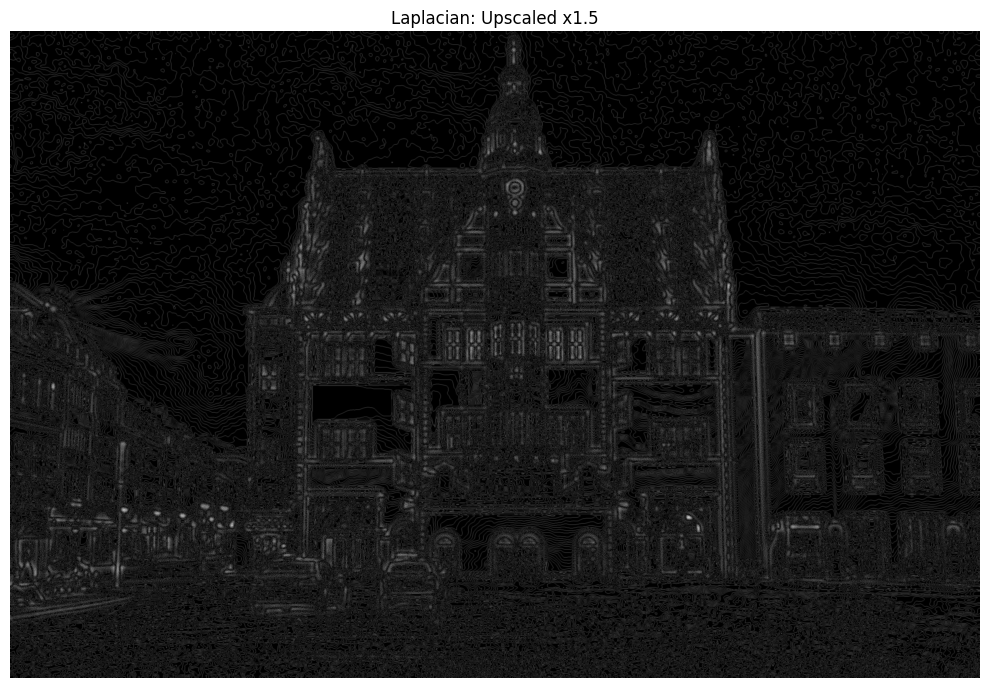

In [ ]:
# blob detection with Laplacian at 1.5 scale
scale = 1.5
h, w = gray.shape
gray_up = cv2.resize(gray, (int(w * scale), int(h * scale)),interpolation=cv2.INTER_CUBIC)


blob_blur_up = cv2.GaussianBlur(gray_up, (0, 0), 4.8)
lap_up = cv2.convertScaleAbs(cv2.Laplacian(blob_blur_up, cv2.CV_64F, ksize=3))

plt.figure(figsize=(10, 8))  
plt.imshow(lap_up, cmap='gray')
plt.title('Laplacian: Upscaled x1.5')
plt.axis('off')
plt.tight_layout()
plt.show()

not much changed, but the scaled version seemed to ignore weak blobs and highlighted the stronger.

Image Stitching 

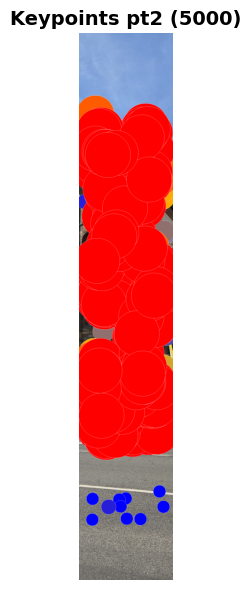

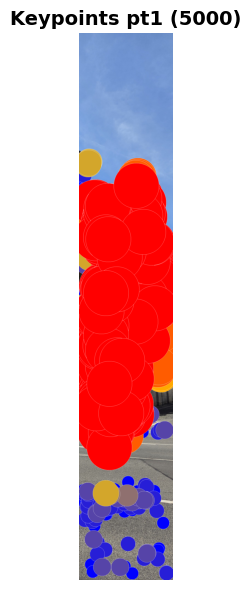

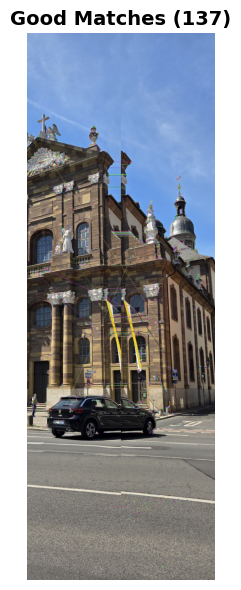

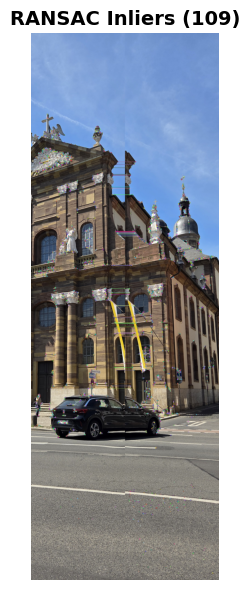

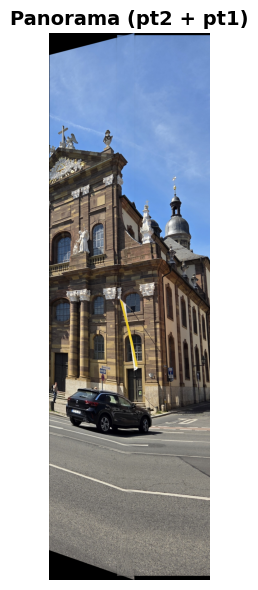

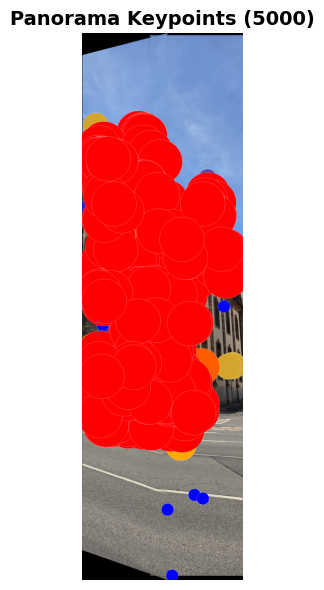

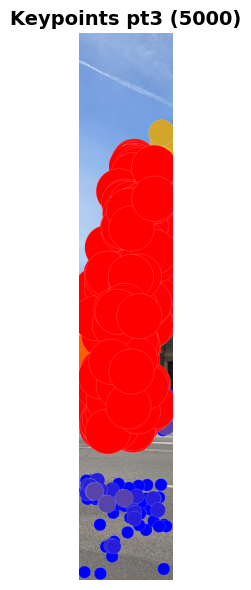

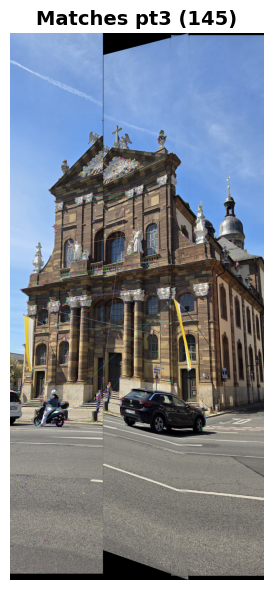

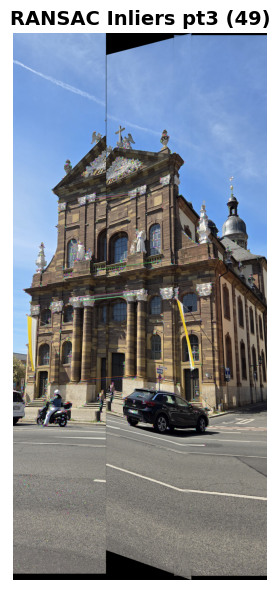

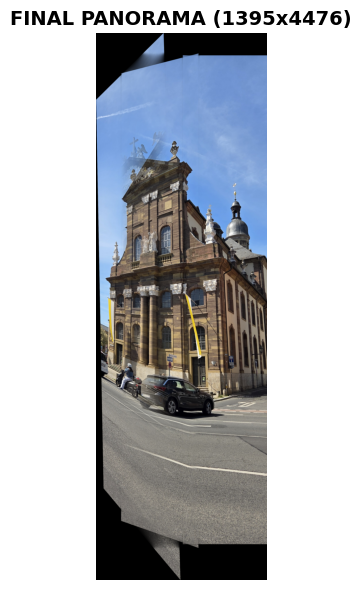

Saved successfully.


In [15]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ─────────────────────────────────────────
# VISUAL HELPERS
# ─────────────────────────────────────────
def show(img_bgr, title="", figsize=(16,6)):
    plt.figure(figsize=figsize)
    plt.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
    plt.title(title, fontsize=14, fontweight="bold")
    plt.axis("off")
    plt.tight_layout()
    plt.show()

def resize_to(img, max_w=1200):
    h, w = img.shape[:2]
    if w > max_w:
        img = cv2.resize(img, (max_w, int(h * max_w / w)))
    return img

def draw_fancy_keypoints(img, keypoints):
    out = img.copy()
    sizes = np.array([k.size for k in keypoints])
    if len(sizes) == 0:
        return out

    s_min, s_max = sizes.min(), sizes.max() + 1e-6

    for kp in keypoints:
        x, y = int(kp.pt[0]), int(kp.pt[1])
        radius = max(3, int(kp.size * 1.5))
        t = (kp.size - s_min) / (s_max - s_min)

        if t < 0.5:
            r, g, b = int(255 * t * 2), int(200 * t * 2), int(255 * (1 - t * 2))
        else:
            r, g, b = 255, int(200 * (1 - (t - 0.5) * 2)), 0

        cv2.circle(out, (x, y), radius, (b, g, r), -1)
        cv2.circle(out, (x, y), radius, (255,255,255), 1)

    return out

# ─────────────────────────────────────────
# ORB + MATCHING
# ─────────────────────────────────────────
def make_ORB():
    return cv2.ORB_create(nfeatures=5000)

def get_good_matches(des_query, des_train):
    bf = cv2.BFMatcher(cv2.NORM_HAMMING)
    raw = bf.knnMatch(des_query, des_train, k=2)

    good = []
    for m, n in raw:
        if m.distance < 0.75 * n.distance:
            good.append(m)

    return good

# ─────────────────────────────────────────
# HOMOGRAPHY
# ─────────────────────────────────────────
def compute_homography(kp_query, kp_train, matches):
    pts_query = np.float32([kp_query[m.queryIdx].pt for m in matches]).reshape(-1,1,2)
    pts_train = np.float32([kp_train[m.trainIdx].pt for m in matches]).reshape(-1,1,2)

    H, mask = cv2.findHomography(
        pts_query, pts_train,
        cv2.RANSAC,
        3.0, confidence=0.999, maxIters=5000
    )
    return H, mask

# ─────────────────────────────────────────
# BLENDING (UNCHANGED → SAME RESULT)
# ─────────────────────────────────────────
def blend_pair(img_left, img_right, H):
    h1, w1 = img_left.shape[:2]
    h2, w2 = img_right.shape[:2]

    corners_right = np.float32([[0,0],[0,h2],[w2,h2],[w2,0]]).reshape(-1,1,2)
    warped_corners = cv2.perspectiveTransform(corners_right, H)
    corners_left = np.float32([[0,0],[0,h1],[w1,h1],[w1,0]]).reshape(-1,1,2)

    all_corners = np.concatenate((corners_left, warped_corners), axis=0)
    [x_min, y_min] = np.int32(all_corners.min(axis=0).ravel() - 0.5)
    [x_max, y_max] = np.int32(all_corners.max(axis=0).ravel() + 0.5)

    t_x = -x_min if x_min < 0 else 0
    t_y = -y_min if y_min < 0 else 0

    T = np.array([[1,0,t_x],[0,1,t_y],[0,0,1]], dtype=np.float32)
    H_trans = T.dot(H)

    nw, nh = x_max - x_min, y_max - y_min

    warped = cv2.warpPerspective(img_right, H_trans, (nw, nh))
    canvas = np.zeros((nh, nw, 3), dtype=np.uint8)
    canvas[t_y:t_y+h1, t_x:t_x+w1] = img_left

    ml = np.zeros((nh, nw), dtype=np.uint8)
    ml[t_y:t_y+h1, t_x:t_x+w1] = 255
    mr = cv2.warpPerspective(np.ones((h2,w2), dtype=np.uint8)*255, H_trans, (nw, nh))

    dl = cv2.GaussianBlur(cv2.distanceTransform(ml, cv2.DIST_L2, 3), (51,51), 0)
    dr = cv2.GaussianBlur(cv2.distanceTransform(mr, cv2.DIST_L2, 3), (51,51), 0)

    total = dl + dr + 1e-6
    al = (dl/total)[:,:,None]
    ar = (dr/total)[:,:,None]

    blended = np.clip(canvas*al + warped*ar, 0,255).astype(np.uint8)

    gray = cv2.cvtColor(blended, cv2.COLOR_BGR2GRAY)
    _, th = cv2.threshold(gray, 15, 255, cv2.THRESH_BINARY)
    cnts, _ = cv2.findContours(th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    if cnts:
        x,y,w,h = cv2.boundingRect(max(cnts, key=cv2.contourArea))
        blended = blended[y:y+h, x:x+w]

    return blended

# ─────────────────────────────────────────
# MAIN PIPELINE
# ─────────────────────────────────────────
import os
BASE = "." if os.path.exists("pt1.jpg") else r"C:\Users\USER\OneDrive - GJU\Desktop\4th Year\MI 2\Homeworks"

part1 = resize_to(cv2.imread(BASE + r"\pt1.jpg"))
part2 = resize_to(cv2.imread(BASE + r"\pt2.jpg"))
part3 = resize_to(cv2.imread(BASE + r"\pt3.jpg"))

orb = make_ORB()

# ───────── PHASE 1 ─────────
gray1 = cv2.cvtColor(part1, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(part2, cv2.COLOR_BGR2GRAY)

kp1, des1 = orb.detectAndCompute(gray1, None)
kp2, des2 = orb.detectAndCompute(gray2, None)

# 🔹 KEYPOINTS
show(draw_fancy_keypoints(part2, kp2), f"Keypoints pt2 ({len(kp2)})")
show(draw_fancy_keypoints(part1, kp1), f"Keypoints pt1 ({len(kp1)})")

# 🔹 MATCHES
matches = get_good_matches(des2, des1)
img_matches = cv2.drawMatches(part2, kp2, part1, kp1, matches[:80], None)
show(img_matches, f"Good Matches ({len(matches)})")

# 🔹 RANSAC
H, mask = compute_homography(kp2, kp1, matches)
inliers = [matches[i] for i in range(len(matches)) if mask[i]]

img_ransac = cv2.drawMatches(part2, kp2, part1, kp1, inliers, None)
show(img_ransac, f"RANSAC Inliers ({len(inliers)})")

# 🔹 STITCH
stitch_21 = blend_pair(part1, part2, H)
show(stitch_21, "Panorama (pt2 + pt1)")

# ───────── PHASE 2 ─────────
gray_21 = cv2.cvtColor(stitch_21, cv2.COLOR_BGR2GRAY)
gray3 = cv2.cvtColor(part3, cv2.COLOR_BGR2GRAY)

kp_21, des_21 = orb.detectAndCompute(gray_21, None)
kp3, des3 = orb.detectAndCompute(gray3, None)

# 🔹 KEYPOINTS
show(draw_fancy_keypoints(stitch_21, kp_21), f"Panorama Keypoints ({len(kp_21)})")
show(draw_fancy_keypoints(part3, kp3), f"Keypoints pt3 ({len(kp3)})")

# 🔹 MATCHES
matches2 = get_good_matches(des3, des_21)
img_matches2 = cv2.drawMatches(part3, kp3, stitch_21, kp_21, matches2[:80], None)
show(img_matches2, f"Matches pt3 ({len(matches2)})")

# 🔹 RANSAC
H2, mask2 = compute_homography(kp3, kp_21, matches2)
inliers2 = [matches2[i] for i in range(len(matches2)) if mask2[i]]

img_ransac2 = cv2.drawMatches(part3, kp3, stitch_21, kp_21, inliers2, None)
show(img_ransac2, f"RANSAC Inliers pt3 ({len(inliers2)})")

# 🔹 FINAL STITCH
final = blend_pair(stitch_21, part3, H2)

# FINAL RESULT
show(final, f"FINAL PANORAMA ({final.shape[1]}x{final.shape[0]})")

cv2.imwrite(BASE + r"\final_panorama.jpg", final)
print("Saved successfully.")